In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load dataset
df = pd.read_csv("/content/city_day.csv")

In [3]:
df.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [4]:
print("Dataset Shape:", df.shape)
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Dataset Shape: (29531, 16)
Total Rows: 29531
Total Columns: 16


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  object 
dtypes: float64(13), object(3)
memory usage: 3.6+ MB


In [6]:
df.isnull().sum()

,0
City,0
Date,0
PM2.5,4598
PM10,11140
NO,3582
NO2,3585
NOx,4185
NH3,10328
CO,2059
SO2,3854


In [7]:
df["AQI_Bucket"].value_counts()

,count
AQI_Bucket,
Moderate,8829
Satisfactory,8224
Poor,2781
Very Poor,2337
Good,1341
Severe,1338


In [8]:
df["AQI"].describe()

,AQI
count,24850.000000
mean,166.463581
std,140.696585
min,13.000000
25%,81.000000
50%,118.000000
75%,208.000000
max,2049.000000


In [9]:
df[df["AQI"] > 500][["City", "Date", "AQI", "AQI_Bucket"]]

,City,Date,AQI,AQI_Bucket
30,Ahmedabad,2015-01-31,514.0,Severe
31,Ahmedabad,2015-02-01,782.0,Severe
32,Ahmedabad,2015-02-02,914.0,Severe
33,Ahmedabad,2015-02-03,660.0,Severe
43,Ahmedabad,2015-02-13,510.0,Severe
...,...,...,...,...
25195,Patna,2019-01-22,525.0,Severe
26374,Talcher,2018-11-27,525.0,Severe
26377,Talcher,2018-11-30,509.0,Severe
26453,Talcher,2019-02-14,570.0,Severe


In [10]:
df.duplicated().sum()


np.int64(0)

In [11]:
df[["AQI", "AQI_Bucket"]].notnull().all(axis=1).sum()

np.int64(24850)

In [12]:
df.loc[df["AQI"] > 500, "AQI_Bucket"].value_counts()

,count
AQI_Bucket,
Severe,543


In [13]:
df[df["AQI"]>500][["PM2.5","PM10","NO","NO2","NOx","NH3","CO","SO2","O3","Benzene","Toluene","Xylene"]]

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene
30,94.52,NaN,24.39,32.66,52.61,NaN,24.39,67.39,111.33,0.24,0.01,7.67
31,135.99,NaN,43.48,42.08,84.57,NaN,43.48,75.23,102.70,0.40,0.04,25.87
32,178.33,NaN,54.56,35.31,72.80,NaN,54.56,55.04,107.38,0.46,0.06,35.61
33,139.70,NaN,30.61,28.40,56.73,NaN,30.61,33.79,73.60,0.17,0.03,11.87
43,103.36,NaN,18.18,39.56,57.33,NaN,18.18,80.43,40.11,11.29,24.35,3.35
...,...,...,...,...,...,...,...,...,...,...,...,...
25195,313.62,NaN,48.09,188.74,78.51,NaN,1.89,31.23,42.25,4.36,25.30,19.30
26374,110.22,528.30,21.49,0.32,21.42,6.88,1.92,26.37,8.15,NaN,NaN,NaN
26377,100.66,507.65,23.27,0.10,22.40,6.98,2.08,28.86,8.24,NaN,NaN,NaN
26453,129.55,567.83,31.84,NaN,27.07,7.46,3.69,25.38,14.16,0.00,NaN,NaN


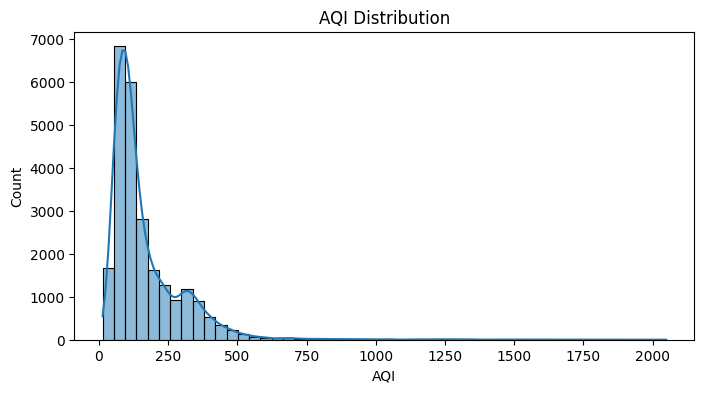

In [14]:
plt.figure(figsize=(8, 4))
sns.histplot(df["AQI"], bins=50, kde=True)
plt.title("AQI Distribution")
plt.show()

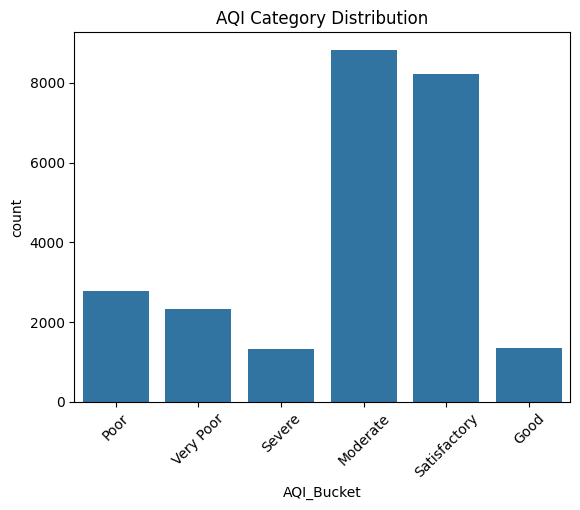

In [15]:
sns.countplot(data=df, x="AQI_Bucket")
plt.title("AQI Category Distribution")
plt.xticks(rotation=45)
plt.show()

In [16]:
# Keep rows where both prediction targets are available
df = df.dropna(subset = ["AQI","AQI_Bucket"])
print("Dataset shape:", df.shape)

Dataset shape: (24850, 16)


In [17]:
df.isnull().sum()

,0
City,0
Date,0
PM2.5,678
PM10,7086
NO,387
NO2,391
NOx,1857
NH3,6536
CO,445
SO2,605


In [18]:
x = df.drop(columns = ["AQI","AQI_Bucket"])
y_reg = df["AQI"]
y_class = df["AQI_Bucket"]

print("Features:", x.shape)
print("Regression target:", y_reg.shape)
print("Classification target:", y_class.shape)

Features: (24850, 14)
Regression target: (24850,)
Classification target: (24850,)


In [19]:
from sklearn.model_selection import train_test_split

In [20]:
x_train, x_test, y_reg_train, y_reg_test, y_class_train, y_class_test = train_test_split(
    x, y_reg, y_class, test_size=0.2, random_state=42, stratify=y_class
)

In [21]:
print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (19880, 14)
Testing data: (4970, 14)


In [22]:
from sklearn.impute import SimpleImputer

In [23]:
imputer = SimpleImputer(strategy  = "median")

In [24]:
for data in [x_train, x_test]:
    data["Date"] = pd.to_datetime(data["Date"])
    data["Year"] = data["Date"].dt.year
    data["Month"] = data["Date"].dt.month
    data["Day"] = data["Date"].dt.day

In [25]:
x_train = pd.get_dummies(x_train,columns = ["City"],dtype = int)
x_test = pd.get_dummies(x_test,columns = ["City"],dtype = int)
x_train,x_test = x_train.align(x_test,join = "left" ,axis = 1, fill_value = 0)

In [26]:
# 1. Remove original Date column
x_train = x_train.drop(columns=["Date"])
x_test = x_test.drop(columns=["Date"])

# 2. Save feature names
feature_names = x_train.columns.tolist()

# 3. Verify
print("Total features:", len(feature_names))
print(feature_names)

Total features: 41
['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'Year', 'Month', 'Day', 'City_Ahmedabad', 'City_Aizawl', 'City_Amaravati', 'City_Amritsar', 'City_Bengaluru', 'City_Bhopal', 'City_Brajrajnagar', 'City_Chandigarh', 'City_Chennai', 'City_Coimbatore', 'City_Delhi', 'City_Ernakulam', 'City_Gurugram', 'City_Guwahati', 'City_Hyderabad', 'City_Jaipur', 'City_Jorapokhar', 'City_Kochi', 'City_Kolkata', 'City_Lucknow', 'City_Mumbai', 'City_Patna', 'City_Shillong', 'City_Talcher', 'City_Thiruvananthapuram', 'City_Visakhapatnam']


In [27]:
x_train = imputer.fit_transform(x_train)
x_test = imputer.transform(x_test)

In [28]:
print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

Training shape: (19880, 41)
Testing shape: (4970, 41)


In [29]:
print("Training missing values:", np.isnan(x_train).sum())
print("Testing missing values:", np.isnan(x_test).sum())

Training missing values: 0
Testing missing values: 0


In [30]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [31]:
print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)
print("First 5 rows:\n", x_train[:5])

Training shape: (19880, 41)
Testing shape: (4970, 41)
First 5 rows:
 [[-0.73246002 -0.08951141 -0.57156724 -0.05265548 -0.27028093 -0.19243642
  -0.30392558 -0.31711418 -0.56053491 -0.12733529 -0.25387675 -0.19145961
  -0.7317824   0.7856115  -1.34002306 -0.23874049 -0.06668014 -0.18747559
  -0.21914773 -0.28629293 -0.10890049 -0.17009483 -0.11124117 -0.28711484
  -0.11777898 -0.29605126 -0.07954566 -0.25040727 -0.14274711 -0.29048813
   4.69993946 -0.17852063 -0.08018356 -0.17716605 -0.28649857 -0.17897016
  -0.25040727 -0.09064129 -0.16962462 -0.20649241 -0.2211571 ]
 [-0.64181242 -0.03862561 -0.53534548 -0.04180186 -1.06097129  0.13739114
   0.71921424 -0.61671431  0.61717016 -0.09975617 -0.39673834 -0.19145961
  -0.7317824  -1.54347141  1.15094505 -0.23874049 -0.06668014 -0.18747559
  -0.21914773  3.49292588 -0.10890049 -0.17009483 -0.11124117 -0.28711484
  -0.11777898 -0.29605126 -0.07954566 -0.25040727 -0.14274711 -0.29048813
  -0.2127687  -0.17852063 -0.08018356 -0.17716605 -0.2

In [32]:
print("Regression:", y_reg_train.shape, y_reg_test.shape)
print("Classification:", y_class_train.shape, y_class_test.shape)

Regression: (19880,) (4970,)
Classification: (19880,) (4970,)


In [33]:
print(y_class_train.value_counts())

AQI_Bucket
Moderate        7063
Satisfactory    6579
Poor            2225
Very Poor       1870
Good            1073
Severe          1070
Name: count, dtype: int64


In [34]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x_train,y_reg_train)
y_pred = model.predict(x_test)

In [35]:
print("Actual AQI values: ", y_reg_test.iloc[:10].values)
print("Predicted AQI values: ",y_pred[:10])

Actual AQI values:  [ 58. 110.  72. 128. 433. 106.  65.  63. 177. 119.]
Predicted AQI values:  [100.66691083  73.93884821  80.90589992 140.19874803 603.43611145
 114.18511802  51.51251641  75.91756928 178.97638031 127.72930973]


In [36]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
mse = mean_squared_error(y_reg_test,y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_reg_test,y_pred)
r2 = r2_score(y_reg_test,y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 28.870343869381713
MSE: 2559.6918557996105
RMSE: 50.59339735380112
R2 Score: 0.8677050599691789


In [37]:
from sklearn.tree import DecisionTreeRegressor
dt_model = DecisionTreeRegressor(random_state = 42)
dt_model.fit(x_train,y_reg_train)
dt_reg_pred = dt_model.predict(x_test)


In [38]:
mse = mean_squared_error(y_reg_test,dt_reg_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_reg_test,dt_reg_pred)
r2 = r2_score(y_reg_test,dt_reg_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 28.064587525150905
MSE: 3167.7128772635815
RMSE: 56.282438444541306
R2 Score: 0.8362801427902605


In [39]:
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(n_estimators = 100, random_state = 42 , n_jobs = -1)
rf_model.fit(x_train,y_reg_train)
rf_reg_pred = rf_model.predict(x_test)

In [40]:
mse = mean_squared_error(y_reg_test,rf_reg_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_reg_test,rf_reg_pred)
r2 = r2_score(y_reg_test,rf_reg_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 19.90255130784708
MSE: 1524.8256562173037
RMSE: 39.049016072332776
R2 Score: 0.9211910143442992


In [41]:
from sklearn.model_selection import GridSearchCV
params = {
    "n_estimators":[100,200],
    "max_depth":[10,20,None]
}
grid = GridSearchCV(
     RandomForestRegressor(random_state = 42,n_jobs = 1),
     params,
     cv = 3,
     scoring = "r2",
     n_jobs = -1,
     verbose=2
)
grid.fit(x_train,y_reg_train)
print("Best Parameters:", grid.best_params_)
print("Best R2 Score:", grid.best_score_)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best Parameters: {'max_depth': 20, 'n_estimators': 200}
Best R2 Score: 0.9002355446984912


In [42]:
best_model = grid.best_estimator_
tuned_pred = best_model.predict(x_test)
print("MAE: ",mean_absolute_error(y_reg_test,tuned_pred))
print("RMSE",np.sqrt(mean_squared_error(y_reg_test,tuned_pred)))
print("R2: ",r2_score(y_reg_test,tuned_pred))

MAE:  19.97795735019394
RMSE 39.34905521065914
R2:  0.9199752795813994


PM2.5      0.485160
CO         0.364248
PM10       0.044592
NO         0.033203
O3         0.013475
NOx        0.008587
SO2        0.007711
NO2        0.006664
Toluene    0.005392
Benzene    0.005139
Day        0.004936
Year       0.004758
Xylene     0.004272
Month      0.002990
NH3        0.002112
dtype: float64


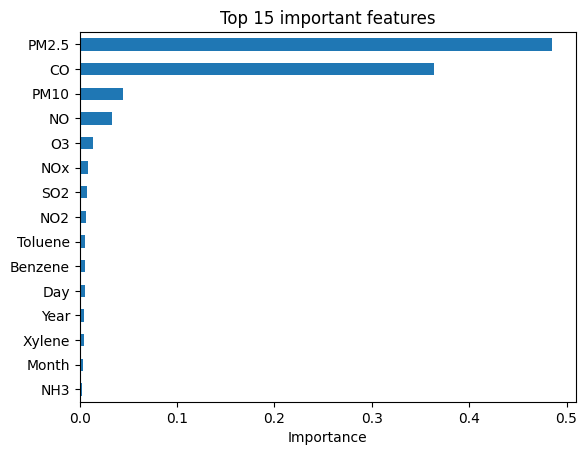

In [43]:
importance = pd.Series(
    best_model.feature_importances_,
    index = imputer.feature_names_in_
 )
importance = importance.sort_values(ascending = False)
print(importance.head(15))

importance.head(15).plot(kind = "barh")
plt.title("Top 15 important features")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.show()

In [44]:
print("Training Distribution:")
print(y_class_train.value_counts())
print("\nTesting Distribution:")
print(y_class_test.value_counts())

Training Distribution:
AQI_Bucket
Moderate        7063
Satisfactory    6579
Poor            2225
Very Poor       1870
Good            1073
Severe          1070
Name: count, dtype: int64

Testing Distribution:
AQI_Bucket
Moderate        1766
Satisfactory    1645
Poor             556
Very Poor        467
Good             268
Severe           268
Name: count, dtype: int64


In [45]:
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(max_iter = 1000)
lr_model.fit(x_train,y_class_train)
lr_pred = lr_model.predict(x_test)
print("first 10 actual: ",y_class_test[:10].values)
print("first 10 predictedl: ",lr_pred[:10])

first 10 actual:  ['Satisfactory' 'Moderate' 'Satisfactory' 'Moderate' 'Severe' 'Moderate'
 'Satisfactory' 'Satisfactory' 'Moderate' 'Moderate']
first 10 predictedl:  ['Satisfactory' 'Satisfactory' 'Satisfactory' 'Moderate' 'Severe'
 'Moderate' 'Satisfactory' 'Satisfactory' 'Moderate' 'Moderate']


In [46]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_class_test,lr_pred)
print("Accuracy: ", accuracy)

Accuracy:  0.7704225352112676


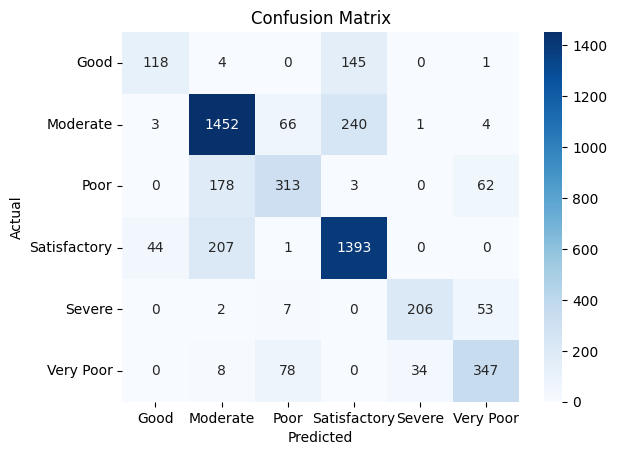

In [47]:
from sklearn.metrics import confusion_matrix
labels = lr_model.classes_
cm = confusion_matrix(y_class_test,lr_pred)
sns.heatmap(cm,fmt = "d",annot = True,cmap = "Blues",xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [48]:
from sklearn.metrics import precision_score
precision = precision_score(y_class_test,lr_pred,average = "weighted")
print("Precision:", precision)

Precision: 0.7673931659451464


In [49]:
from sklearn.metrics import recall_score
recall = recall_score(y_class_test,lr_pred,average = "weighted")
print("Recall:", recall)

Recall: 0.7704225352112676


In [50]:
from sklearn.metrics import f1_score
f1 = f1_score(y_class_test,lr_pred,average = "weighted")
print("F1 Score:", f1)

F1 Score: 0.7658902237263322


In [51]:
from sklearn.metrics import classification_report
print(classification_report(y_class_test,lr_pred))

              precision    recall  f1-score   support

        Good       0.72      0.44      0.55       268
    Moderate       0.78      0.82      0.80      1766
        Poor       0.67      0.56      0.61       556
Satisfactory       0.78      0.85      0.81      1645
      Severe       0.85      0.77      0.81       268
   Very Poor       0.74      0.74      0.74       467

    accuracy                           0.77      4970
   macro avg       0.76      0.70      0.72      4970
weighted avg       0.77      0.77      0.77      4970



In [52]:
from sklearn.tree import DecisionTreeClassifier
dt_class = DecisionTreeClassifier(random_state = 42)
dt_class.fit(x_train,y_class_train)
dt_class_pred = dt_class.predict(x_test)

In [53]:
print("Accuracy:", accuracy_score(y_class_test, dt_class_pred))
print("Precision:", precision_score(y_class_test, dt_class_pred, average="weighted"))
print("Recall:", recall_score(y_class_test, dt_class_pred, average="weighted"))
print("F1 Score:", f1_score(y_class_test, dt_class_pred, average="weighted"))

Accuracy: 0.7329979879275654
Precision: 0.7334046378674932
Recall: 0.7329979879275654
F1 Score: 0.7329117384541948


In [54]:
from  sklearn.ensemble import RandomForestClassifier
rf_class = RandomForestClassifier(n_estimators = 100, random_state = 42, n_jobs = -1)
rf_class.fit(x_train,y_class_train)
rf_class_pred = rf_class.predict(x_test)
print(rf_class_pred[:10])

['Satisfactory' 'Moderate' 'Satisfactory' 'Moderate' 'Severe'
 'Satisfactory' 'Satisfactory' 'Satisfactory' 'Moderate' 'Moderate']


In [55]:
print("Accuracy:", accuracy_score(y_class_test, rf_class_pred))
print("Precision:", precision_score(y_class_test, rf_class_pred, average="weighted"))
print("Recall:", recall_score(y_class_test, rf_class_pred, average="weighted"))
print("F1 Score:", f1_score(y_class_test, rf_class_pred, average="weighted"))

Accuracy: 0.8160965794768612
Precision: 0.8149865194816401
Recall: 0.8160965794768612
F1 Score: 0.814312438260804


In [56]:
from sklearn.neighbors import KNeighborsClassifier
knn_model = KNeighborsClassifier(n_neighbors = 5)
knn_model.fit(x_train,y_class_train)
knn_pred = knn_model.predict(x_test)

In [57]:
print("Accuracy:", accuracy_score(y_class_test, knn_pred))
print("Precision:", precision_score(y_class_test, knn_pred, average="weighted"))
print("Recall:", recall_score(y_class_test, knn_pred, average="weighted"))
print("F1 Score:", f1_score(y_class_test, knn_pred, average="weighted"))

Accuracy: 0.7561368209255533
Precision: 0.7533801425361503
Recall: 0.7561368209255533
F1 Score: 0.7537667572525313


In [58]:
from sklearn.svm import SVC
svm_model = SVC(kernel = "rbf")
svm_model.fit(x_train,y_class_train)
svm_pred = svm_model.predict(x_test)

In [59]:
print("Accuracy:", accuracy_score(y_class_test, svm_pred))
print("Precision:", precision_score(y_class_test, svm_pred, average="weighted"))
print("Recall:", recall_score(y_class_test, svm_pred, average="weighted"))
print("F1 Score:", f1_score(y_class_test, svm_pred, average="weighted"))

Accuracy: 0.7822937625754527
Precision: 0.780670541293346
Recall: 0.7822937625754527
F1 Score: 0.7767955603220759


In [60]:
print(classification_report(y_class_test, rf_class_pred))

              precision    recall  f1-score   support

        Good       0.79      0.65      0.71       268
    Moderate       0.82      0.87      0.84      1766
        Poor       0.74      0.64      0.68       556
Satisfactory       0.84      0.86      0.85      1645
      Severe       0.88      0.78      0.82       268
   Very Poor       0.77      0.81      0.79       467

    accuracy                           0.82      4970
   macro avg       0.81      0.77      0.78      4970
weighted avg       0.81      0.82      0.81      4970



In [62]:
print("Regression Model:", type(rf_model).__name__)
print("Classification Model:", type(rf_class).__name__)

print("Training Shape:", x_train.shape)
print("Feature Names:", len(feature_names))
print("Imputer Features:", len(imputer.statistics_))
print("Scaler Features:", len(scaler.mean_))

Regression Model: RandomForestRegressor
Classification Model: RandomForestClassifier
Training Shape: (19880, 41)
Feature Names: 41
Imputer Features: 41
Scaler Features: 41


In [69]:

import pickle
import os

os.makedirs("models", exist_ok=True)

aqi_data = {
    "reg_model": rf_model,
    "class_model": rf_class,
    "feature_names": feature_names,
    "imputer_stats": imputer.statistics_,
    "scaler_mean": scaler.mean_,
    "scaler_scale": scaler.scale_
}

with open("models/aqi_model.pkl", "wb") as file:
    pickle.dump(aqi_data, file)

print("AQI model saved successfully!")


AQI model saved successfully!


In [70]:
print(os.listdir("models"))

['aqi_preprocessing.pkl', 'scaler_mean.pkl', 'aqi_model.pkl', 'aqi_classification.pkl', 'imputer_statistics.pkl', 'scaler_scale.pkl', 'aqi_regression.pkl']
